**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 7**
Análisis de Componentes Principales (PCA)

---

*   **GRUPO #1**
*   ENMANUEL ABREU - A01841472
*   LUIS ACOSTA - A01027765
*   DIANA ACOSTA - A01841464
*   EDUARDO AGUA - A01841466

En esta actividad trabajarás con el archivo `automobile_dataset.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de automóviles, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar diferentes aspectos de los vehículos y sus precios, e incluyen información sobre el fabricante, tipo de motor, dimensiones, peso, rendimiento de combustible y otras especificaciones técnicas. Los indicadores incluidos son:

* `symboling`: Nivel de riesgo del seguro del automóvil, de -3 (bajo riesgo) a +3 (alto riesgo)
* `normalized_losses`: Pérdidas normalizadas del seguro (valor numérico de la aseguradora, algunas veces faltante)
* `make`: Marca del automóvil (por ejemplo, Audi, BMW, Honda)
* `fuel_type`: Tipo de combustible (gasolina o diésel)
* `aspiration`: Tipo de aspiración del motor (normal o turbo)
* `num_doors`: Número de puertas del automóvil (dos o cuatro)
* `body_style`: Estilo de carrocería (sedán, hatchback, wagon, hardtop, convertible)
* `drive_wheels`: Tipo de tracción (fwd: delantera, rwd: trasera, 4wd: en las cuatro ruedas)
* `engine_location`: Ubicación del motor (delantero o trasero)
* `wheel_base`: Distancia entre ejes (en pulgadas)
* `length`: Largo total del automóvil (en pulgadas)
* `width`: Ancho total del automóvil (en pulgadas)
* `height`: Altura total del automóvil (en pulgadas)
* `curb_weight`: Peso del automóvil sin carga (en libras)
* `engine_type`: Tipo de motor (OHV, OHC, DOHC, etc.)
* `num_cylinders`: Número de cilindros del motor
* `engine_size`: Tamaño del motor (en cc)
* `fuel_system`: Sistema de combustible (por ejemplo, mpfi, 2bbl, 4bbl)
* `bore`: Diámetro del cilindro (en pulgadas)
* `stroke`: Carrera del pistón (en pulgadas)
* `compression_ratio`: Relación de compresión del motor
* `horsepower`: Potencia del motor (en caballos de fuerza)
* `peak_rpm`: Revoluciones máximas por minuto
* `city_mpg`: Rendimiento de combustible en ciudad (millas por galón)
* `highway_mpg`: Rendimiento de combustible en carretera (millas por galón)
* `price`: Precio del automóvil (en dólares estadounidenses) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

Como primer paso, importamos las bibliotecas necesarias.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

1. Descarga el archivo: `automobile_dataset.csv` y guarda, en un dataframe (`cars_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Al revisar los primeros registros, notarás que la columna `normalized_losses` contiene el símbolo `?`. Esto sugiere que se utilizó para indicar valores faltantes. Identifica todas las columnas que presentan este símbolo.
* Sustituye el símbolo `?` por valores faltantes (`NaN`) y convierte las columnas al tipo de dato adecuado. Esto es necesario porque la presencia del símbolo pudo haber hecho que pandas las interpretara como object, aunque en realidad no lo fueran.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [29]:
cars_df = pd.read_csv('/content/drive/MyDrive/Ciencia de Datos/Semana 7/automobile_dataset.csv')
cars_df.head()

,symboling,normalized_losses,make,fuel_type,aspiration,num_doors,body_style,drive_wheels,engine_location,wheel_base,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.4,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.4,8.0,115,5500,18,22,17450


**Punto 1.** Resumen de datos con `info()`

In [30]:
cars_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

***Respuesta:*** De acuerdo con los datos obtenidos mediante la función `info()` tenemos:
*   **12 columnas numéricas:** 7 de tipo `int64` y 5 de tipo `float64`.
*   **14 columnas de texto:** de tipo `object`.

**Punto 2.** Identificamos las columnas que contienen el símbolo '?'. Además de `normalized_losses`.

In [31]:
signos = (cars_df == '?').sum()

display(signos[signos > 0].to_frame('Cantidad de ?'))

,Cantidad de ?
normalized_losses,41
bore,4
stroke,4
horsepower,2
peak_rpm,2


***Respuesta:** Las columnas que presentan el símbolo '?' son **5**:*

*   ***normalized_losses:** 41 registros*
*   ***bore:** 4 registros*
*   ***stroke:** 4 registros*
*   ***horsepower:** 2 registros*
*   ***peak_rpm:** 2 registros*

*En total hay **53 valores** con '?'. Las cinco son variables numéricas que pandas leyó como texto (object) por la presencia de este símbolo.*

**Punto 3.** Sustituimos el símbolo `?` por valores faltantes (`NaN`) y conviertimos las columnas al tipo de dato adecuado.

Paso 1. Una vez identificadas las columnas, sustituimos el símbolo.

In [32]:
cars_df = cars_df.replace('?', np.nan)

Paso 2. Convertimos específicamente las cinco columnas al tipo de dato correcto.

In [62]:
cols_convertir = ['normalized_losses', 'bore', 'stroke',
                  'horsepower', 'peak_rpm']

cars_df[cols_convertir] = cars_df[cols_convertir].apply(
    pd.to_numeric
)

Paso 3. Corroboramos que las columnas tengan los datos corregidos. Utilizamos `info()` de nuevo.

In [34]:
cars_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_doors          205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    int64  
 14  engine_type        205 non-null    object 
 15  num_cylinders      205 non-null    int64  
 16  engine_size        205 non

*   ***Respuesta:*** *Después de la conversión tenemos **17 columnas numéricas** y **9 categóricas**. Los valores faltantes permanecen como **NaN** para tratarlos
posteriormente.*

# Análisis exploratorio de datos (univariado)

2. Antes de iniciar con el análisis univariado, verifica si hay registros duplicados e imprime el porcentaje de faltantes por columna.
* Obtén las estadísticas descriptivas, separado las numéricas (incluye asimetría y curtosis) y las categóricas (incluye tablas de frecuencias).
* Genera histogramas para las numéricas y diagramas de barras para las categóricas.

Revisamos que no haya registros duplicados.

In [35]:
print("Registros duplicados:", cars_df.duplicated().sum())

Registros duplicados: 0


***Respuesta:***

*No existen registros duplicados.*

Hacemos un chequeo de los valores faltantes y obtenemos el porcentaje en orden de mayor a menor.

In [36]:
faltantes = cars_df.isna().mean() * 100
faltantes.round(2).to_frame('Faltantes (%)')

,Faltantes (%)
symboling,0.00
normalized_losses,20.00
make,0.00
fuel_type,0.00
aspiration,0.00
num_doors,0.00
body_style,0.00
drive_wheels,0.00
engine_location,0.00
wheel_base,0.00


***Respuesta:***

*Los porcentajes de faltantes son:*

*   **`normalized_losses`:** 20%
*   **`bore`:** 1.95%
*   **`stroke`:** 1.95%
*   **`horsepower`:** 0.98%
*   **`peak_rpm`:** 0.98%

**Punto 1.** Obtenemos las estadísticas descriptivas.

Paso 1. Hacemos una lista de las variables numéricas.

In [37]:
num_cols = cars_df.select_dtypes(include='number').columns

Paso 2. Obtención de las características descriptivas de las variables numéricas (`num_cols`).

In [38]:
estadisticas_numericas = cars_df[num_cols].describe().T

estadisticas_numericas['asimetria'] = cars_df[num_cols].skew()
estadisticas_numericas['curtosis'] = cars_df[num_cols].kurt()

estadisticas_numericas

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
symboling,205.0,0.834146,1.245307,-2.00,0.00,1.00,2.00,3.00,0.211072,-0.676271
normalized_losses,164.0,122.000000,35.442168,65.00,94.00,115.00,150.00,256.00,0.765976,0.525440
wheel_base,205.0,98.756585,6.021776,86.60,94.50,97.00,102.40,120.90,1.050214,1.017039
length,205.0,174.049268,12.337289,141.10,166.30,173.20,183.10,208.10,0.155954,-0.082895
width,205.0,65.907805,2.145204,60.30,64.10,65.50,66.90,72.30,0.904003,0.702764
height,205.0,53.724878,2.443522,47.80,52.00,54.10,55.50,59.80,0.063123,-0.443812
curb_weight,205.0,2555.565854,520.680204,1488.00,2145.00,2414.00,2935.00,4066.00,0.681398,-0.042854
num_cylinders,205.0,4.380488,1.080854,2.00,4.00,4.00,4.00,12.00,2.817459,13.714866
engine_size,205.0,126.907317,41.642693,61.00,97.00,120.00,141.00,326.00,1.947655,5.305682
bore,201.0,3.329751,0.273539,2.54,3.15,3.31,3.59,3.94,0.020016,-0.828945


Paso 3. Hacemos una lista de las variables categóricas.

In [39]:
cat_cols = cars_df.select_dtypes(include=['category','object']).columns

Paso 4. Obtención de las características descriptivas de las variables categóricas (`cat_cols`) y las tablas de frecuencia.

In [40]:
cars_df[cat_cols].describe().T

for col in cat_cols:
    print(f"\nFrecuencias de {col}:")
    display(cars_df[col].value_counts(dropna=False).to_frame('Frecuencia'))



Frecuencias de make:


,Frecuencia
make,
toyota,32
nissan,18
mazda,17
mitsubishi,13
honda,13
subaru,12
volkswagen,12
volvo,11
peugot,11



Frecuencias de fuel_type:


,Frecuencia
fuel_type,
gas,185
diesel,20



Frecuencias de aspiration:


,Frecuencia
aspiration,
std,168
turbo,37


... (8 outputs left out)


Frecuencias de engine_type:


,Frecuencia
engine_type,
ohc,148
ohcf,15
ohcv,13
dohc,12
l,12
rotor,4
dohcv,1



Frecuencias de fuel_system:


,Frecuencia
fuel_system,
mpfi,94
2bbl,66
idi,20
1bbl,11
spdi,9
4bbl,3
mfi,1
spfi,1


**Punto 2.** Generación de histogramas para las numéricas y diagramas de barras para las categóricas.

Paso 1. Histogramas.

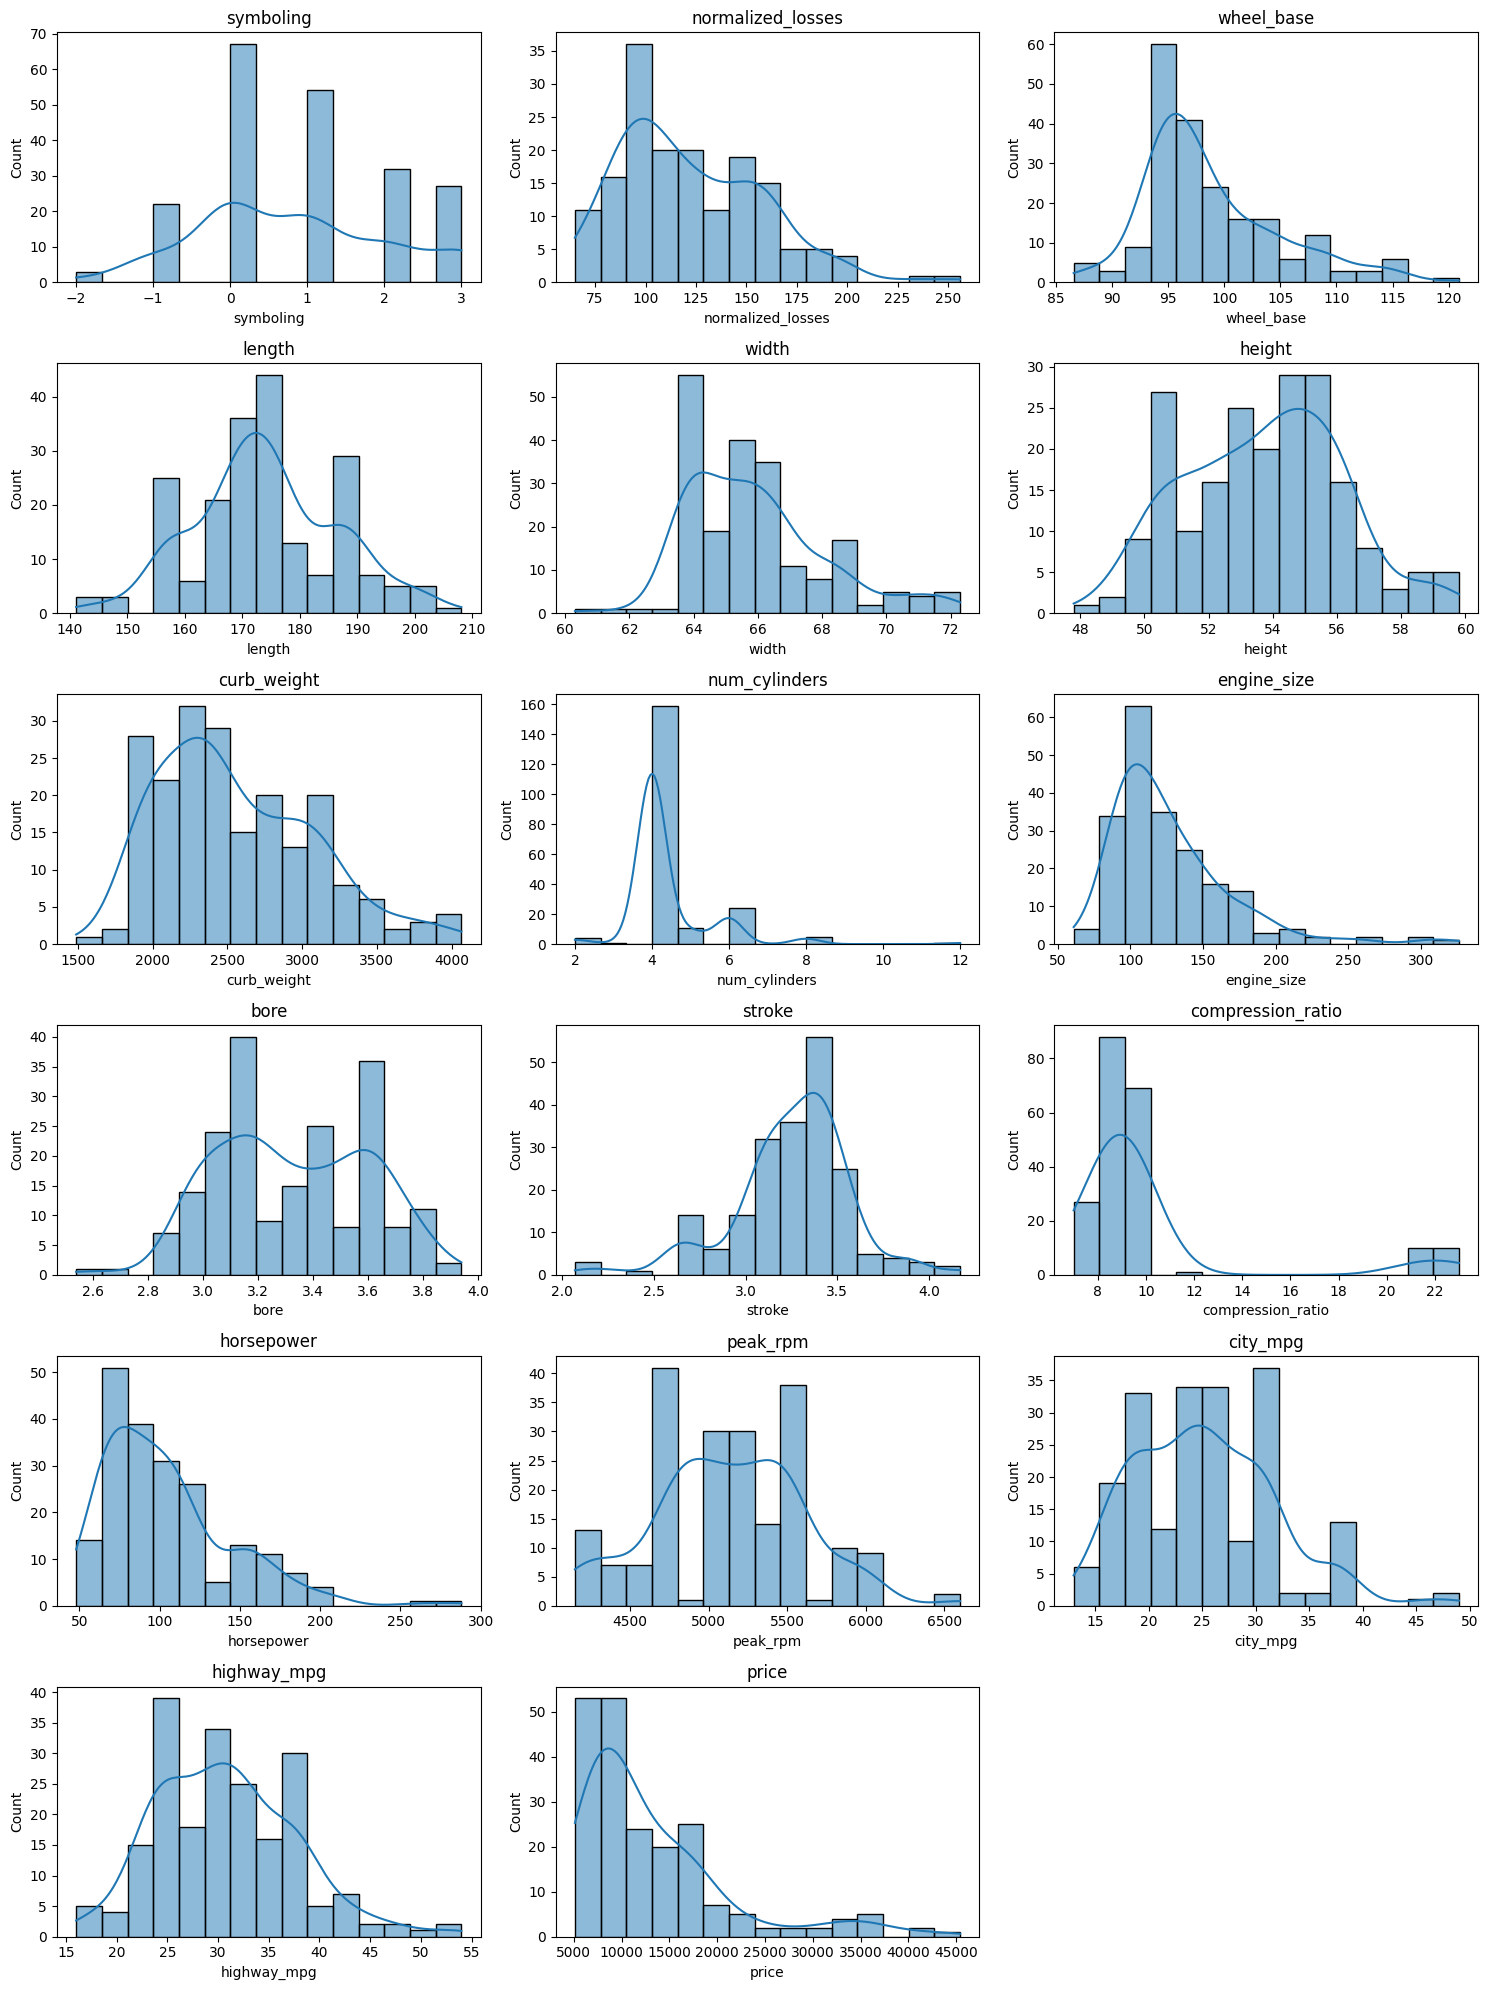

In [41]:
fig, axes = plt.subplots(6, 3, figsize=(15, 20))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=cars_df, x=col, bins=15,
                 kde=True, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


Paso 2. Diagramas de barras.

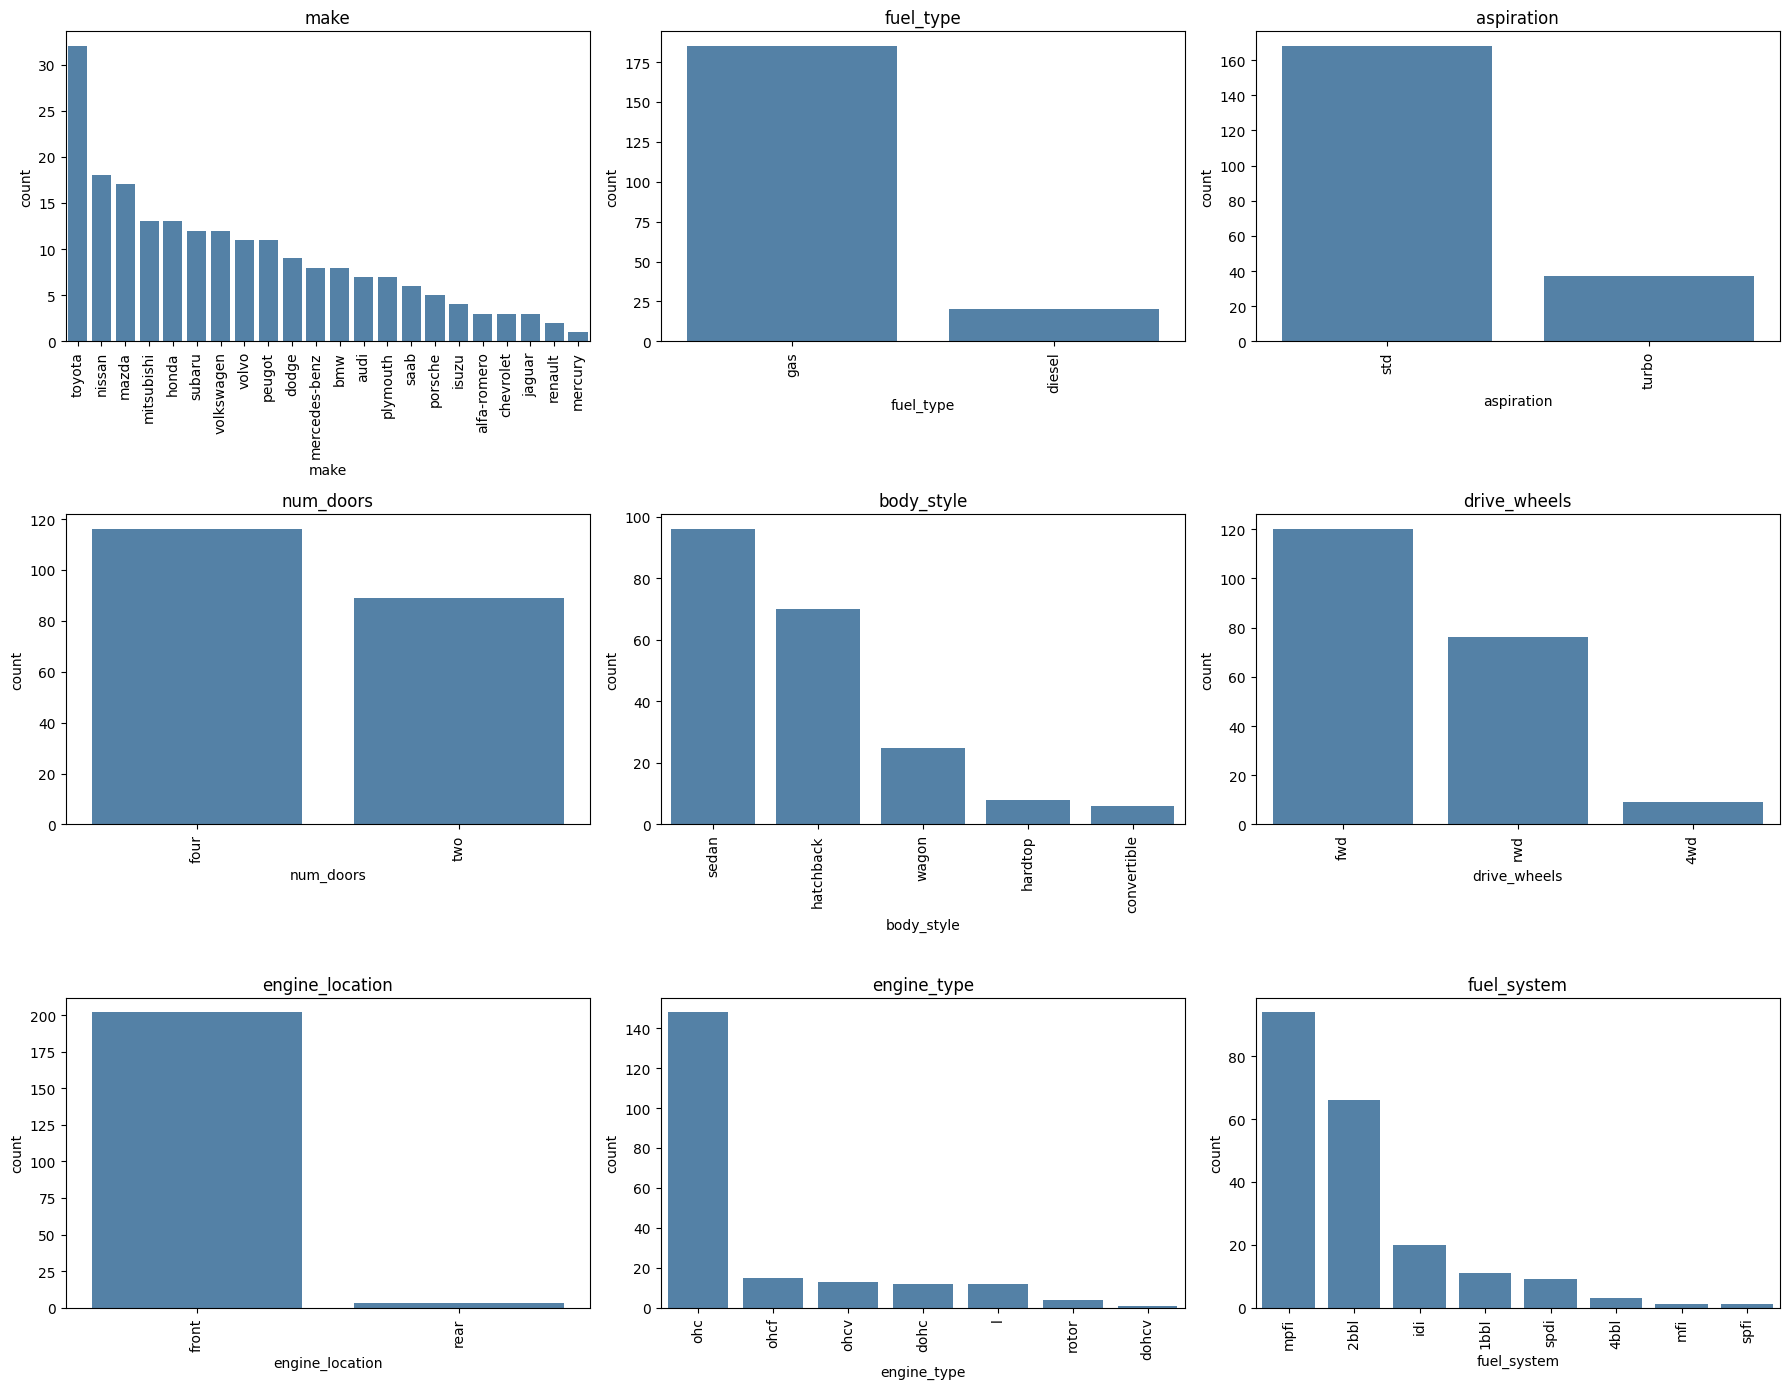

In [42]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    orden = cars_df[col].value_counts().index

    sns.countplot(data=cars_df, x=col, order=orden,
                  ax=axes[i], color='steelblue')

    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()


# Análisis exploratorio de datos (bivariado)

3. Genera algunos gráficos bivariados para familiarizarte con el conjunto de datos:
* Gráfico de barras apiladas normalizadas que muestra la distribución de los tipos de tracción para cada fabricante.
* Diagrama de cajas para visualizar cómo se distribuye el precio de los automóviles según el estilo de carrocería. Esto permitirá comparar la mediana, los cuartiles y la presencia de valores atípicos entre los diferentes tipos de carrocería.
* Gráfico de barras que muestre los 10 automóviles más caros, ordenados de mayor a menor precio, con cada barra diferenciada con color por fabricante.
* Diagrama de dispersión para explorar la relación entre el tamaño del motor y el precio de los automóviles. Diferencia con colores los puntos según el tipo de aspiración y con el tamaño de los puntos el número de puertas.

**Nota.** Debes incluir en cada gráfico una conclusión de lo observado.

**Punto 1.** Gráfico de barras apiladas normalizadas que muestra la distribución de los tipos de tracción para cada fabricante.

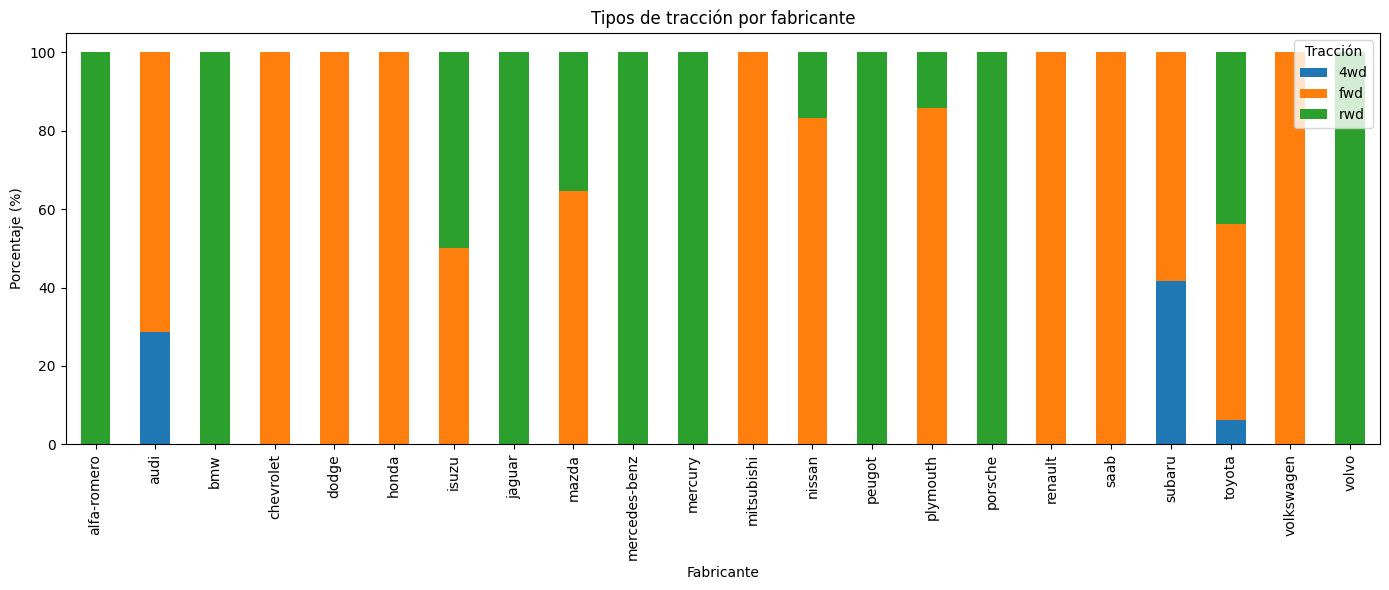

In [43]:
traccion = pd.crosstab(
    cars_df['make'],
    cars_df['drive_wheels'],
    normalize='index'
) * 100

traccion.plot(kind='bar',
           stacked=True,
           figsize=(14, 6))

plt.title('Tipos de tracción por fabricante')
plt.xlabel('Fabricante')
plt.ylabel('Porcentaje (%)')
plt.legend(title='Tracción')
plt.tight_layout()
plt.show()


***Conclusión — Gráfico 1 (Tracción por fabricante):***
La configuración de tracción muestra una clara especialización según el posicionamiento comercial de cada fabricante:
* **Especialización en tracción trasera (`rwd`, 100%):** Ocho marcas —`alfa-romero`, `bmw`, `jaguar`, `mercedes-benz`, `mercury`, `peugot`, `porsche` y `volvo`— comercializan exclusivamente vehículos `rwd`, característicos de segmentos ejecutivos, de lujo y deportivos.
* **Especialización en tracción delantera (`fwd`, 100%):** Siete fabricantes —`chevrolet`, `dodge`, `honda`, `mitsubishi`, `renault`, `saab` y `volkswagen`— emplean únicamente `fwd`, priorizando eficiencia de combustible y aprovechamiento del espacio interior en automóviles compactos y medianos.
* **Tracción en las cuatro ruedas (`4wd`) y oferta diversificada:** Solo tres fabricantes ofrecen `4wd`: `subaru` (**41.7%** de sus modelos), `audi` (**28.6%**) y `toyota` (**6.2%**). Sobresale `toyota` como la única marca con vehículos en los tres tipos de tracción (`fwd` 50.0%, `rwd` 43.8% y `4wd` 6.2%).

**Punto 2.** Diagrama de cajas para visualizar cómo se distribuye el precio de los automóviles según el estilo de carrocería.

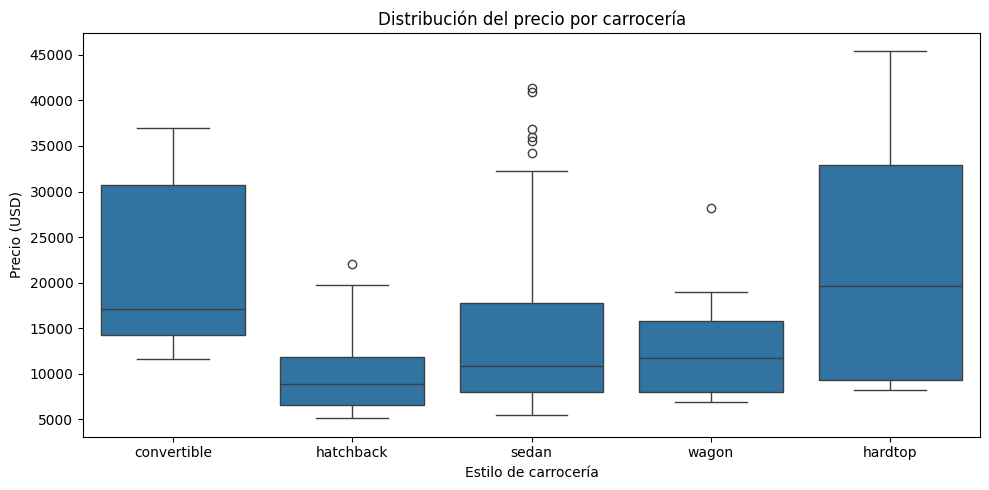

In [44]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=cars_df, x='body_style', y='price')

plt.title('Distribución del precio por carrocería')
plt.xlabel('Estilo de carrocería')
plt.ylabel('Precio (USD)')
plt.tight_layout()
plt.show()


***Conclusión — Gráfico 2 (Precio por estilo de carrocería):*** Los vehículos hardtop presentan la mediana de precio más elevada, mientras que los hatchback tienen la más baja. Esto indica diferencias importantes en el precio según el estilo de carrocería.

**Punto 3.** Gráfico de barras que muestre los 10 automóviles más caros.

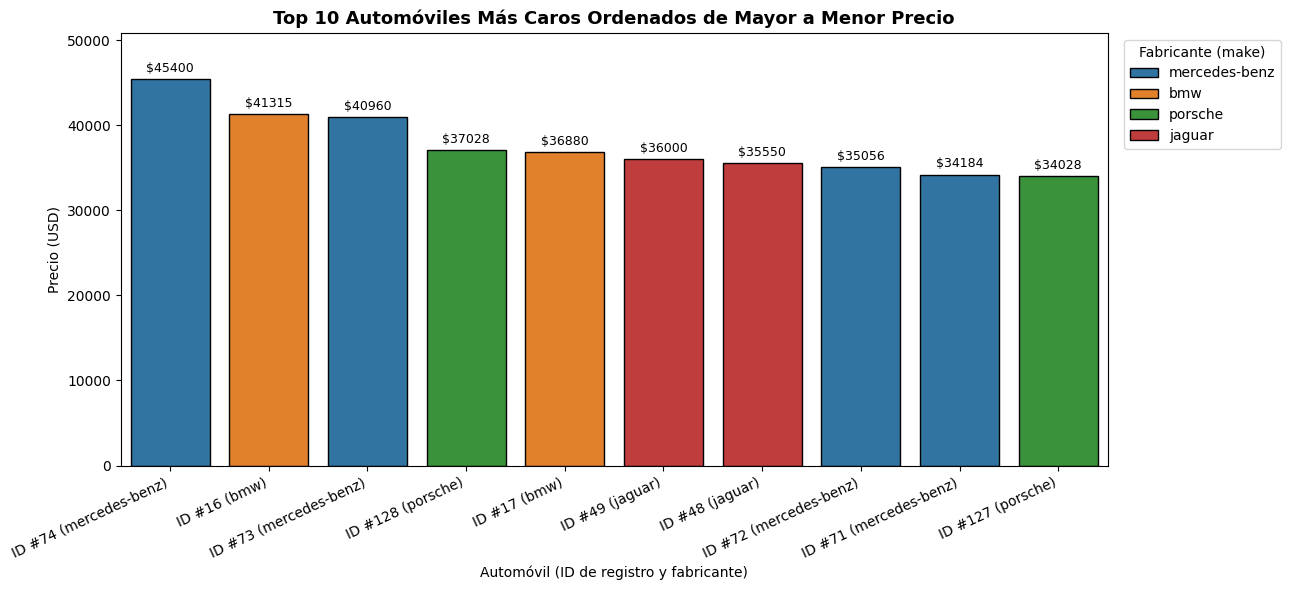

In [45]:
top10_caros = cars_df.nlargest(10, 'price').copy()
top10_caros['automovil'] = [f"ID #{idx} ({row['make']})" for idx, row in top10_caros.iterrows()]

plt.figure(figsize=(13, 6))
ax = sns.barplot(
    data=top10_caros,
    x='automovil',
    y='price',
    hue='make',
    dodge=False,
    palette='tab10',
    edgecolor='black'
)
for container in ax.containers:
    ax.bar_label(container, fmt='$%.0f', padding=3, fontsize=9)

plt.title('Top 10 Automóviles Más Caros Ordenados de Mayor a Menor Precio', fontsize=13, fontweight='bold')
plt.xlabel('Automóvil (ID de registro y fabricante)')
plt.ylabel('Precio (USD)')
plt.xticks(rotation=25, ha='right')
plt.ylim(0, top10_caros['price'].max() * 1.12)
plt.legend(title='Fabricante (make)', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()


***Conclusión — Gráfico 3 (Top 10 automóviles más caros):***
Los **10 vehículos individuales de mayor precio** se ubican entre `$34,028` y `$45,400` USD, y pertenecen en su totalidad a únicamente **cuatro fabricantes europeos de alta gama**:
* **`mercedes-benz`** domina el listado con **4 de los 10 automóviles** (`ID #74`, `ID #73`, `ID #72` e `ID #71`), incluyendo el vehículo más caro de todo el conjunto de datos (`ID #74`, carrocería *hardtop*, con `$45,400` USD) y el tercero (`ID #73` con `$40,960` USD).
* **`bmw`** ocupa el segundo y quinto lugar (`ID #16` con `$41,315` USD e `ID #17` con `$36,880` USD).
* **`porsche`** aporta dos deportivos (`ID #128` con `$37,028` USD e `ID #127` con `$34,028` USD) y **`jaguar`** dos sedanes de gran cilindrada (`ID #49` con `$36,000` USD e `ID #48` con `$35,550` USD). Ninguna marca asiática ni estadounidense figura dentro de este decil superior.

**Punto 4.** Diagrama de dispersión para explorar la relación entre el tamaño del motor y el precio de los automóviles.

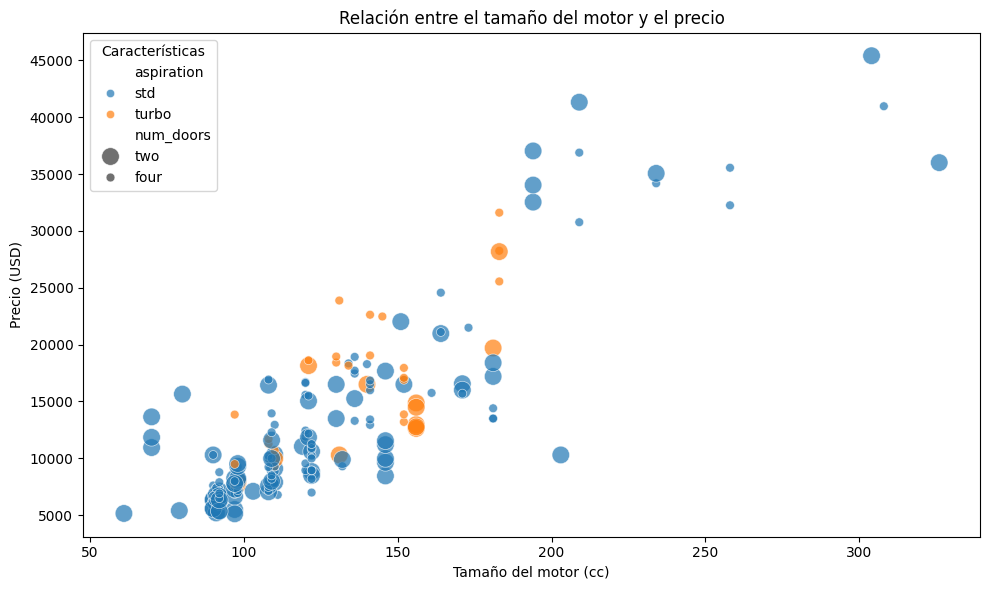

In [46]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cars_df,
    x='engine_size',
    y='price',
    hue='aspiration',
    size='num_doors',
    sizes=(40, 160),
    alpha=0.7
)

plt.title('Relación entre el tamaño del motor y el precio')
plt.xlabel('Tamaño del motor (cc)')
plt.ylabel('Precio (USD)')
plt.legend(title='Características')
plt.tight_layout()
plt.show()


***Conclusión — Gráfico 4 (Tamaño del motor vs. precio, aspiración y puertas):*** Existe una relación positiva fuerte entre el tamaño del motor y el precio, los vehículos con motores más grandes tienden a ser más costosos. Los colores y tamaños de los puntos permiten explorar si la aspiración y el número de puertas modifican visualmente este patrón.

4. Genera un mapa de calor de la matriz de correlación entre las variables numéricas del conjunto de datos, mostrando los valores de correlación en cada celda.
* ¿Cuáles son las tres variables más correlacionadas con el precio?

En el análisis de correlación se observa que existen muchos pares de variables altamente correlacionadas, lo que puede afectar el desempeño de los modelos de regresión. PCA resulta útil no solo para reducir la dimensionalidad, sino también porque los componentes principales son ortogonales entre sí, es decir, tienen correlación cero, evitando problemas de multicolinealidad. Esto lo podrás comprobrar más adelante.

**Punto 1.** Mapa de calor y variables con alta correlación respecto al precio.

Paso 1. Matriz de correlación.

In [47]:
corr = cars_df[num_cols].corr()

Paso 2. Generamos el mapa de calor.

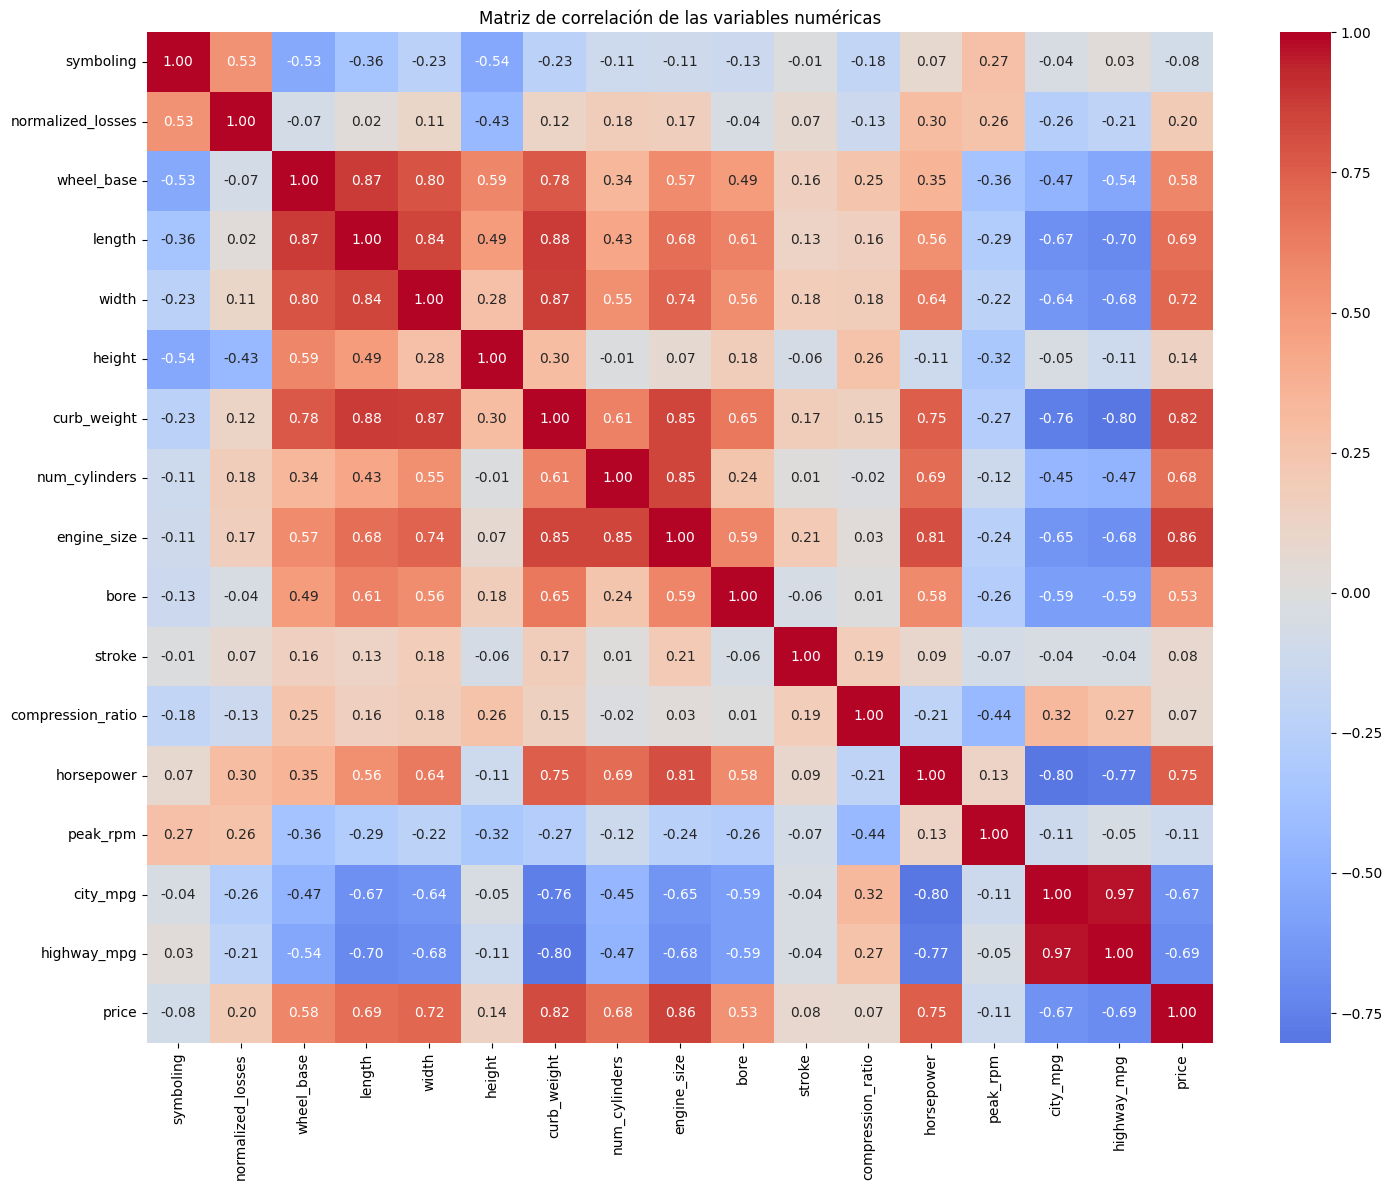

In [48]:
plt.figure(figsize=(15, 12))

sns.heatmap(corr, annot=True, fmt='.2f',
            cmap='coolwarm', center=0)

plt.title('Matriz de correlación de las variables numéricas')
plt.tight_layout()
plt.show()


***Respuesta:*** Identificamos las 3 variables más correlacionadas con el precio (`price`):

1. **`engine_size`** ($r = 0.8603$)
2. **`curb_weight`** ($r = 0.8198$)
3. **`horsepower`** ($r = 0.7498$)

El tamaño del motor, el peso sin carga y la potencia presentan asociaciones positivas fuertes con el precio. Esto sugiere que las características mecánicas y físicas del vehículo son importantes para explicar su valor comercial.

# Ingeniería de características

5. Realiza las siguientes operaciones de ingeniería de características en las variables numéricas:
* Considera `price` como la variable objetivo y guárdala en `y`. Separa los predictores numéricos en `X`. Con base en estos datos, ¿cuántos componentes principales se generarán al aplicar PCA?
* Aplica `SimpleImputer` sobre `X` para tratar los valores faltantes, justificando la estrategia de imputación seleccionada.
* Realiza el escalamiento del conjunto `X` ya imputado, para que todas las variables contribuyan equitativamente y ninguna domine el análisis por tener una escala mayor.

PCA está diseñado principalmente para variables numéricas y funciona encontrando combinaciones lineales de las variables originales que capturan la mayor varianza en los datos. Normalmente se recomienda eliminar las variables categóricas antes de aplicar PCA y luego concatenarlas nuevamente con los resultados de PCA si se desea.

**Punto 1.** La variable objetivo y los predictores numéricos.

Paso 1. Creamos la variable objetivo y las variables predictoras numéricas.

In [49]:
y = cars_df['price']
X = cars_df[num_cols].drop(columns='price')

print("Variables predictoras:", X.shape)
print("Componentes principales posibles:", X.shape[1])


Variables predictoras: (205, 16)
Componentes principales posibles: 16


***Respuesta:*** Se estableció `price` como variable objetivo (`y`) y se separaron las variables predictoras numéricas en `X`. El conjunto de predictores contiene $205$ registros y $16$ variables, por lo que se podrán generar como máximo $16$ componentes principales mediante PCA, suponiendo que no exista dependencia lineal entre las variables.

**Punto 2.** Aplicación de `SimpleImputer` sobre `X` para tratar los valores faltantes.

Paso 1. Se crea el imputador utilizando la mediana y se imputan los valores faltantes.

In [50]:
imputer = SimpleImputer(strategy='median')

X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

Paso 2. Comprobamos el resultado.

In [51]:
X_imputed.isna().sum().sum()


np.int64(0)

***Justificación de la estrategia de imputación (`strategy='median'`):***

Las cinco variables de `X` con registros faltantes (`normalized_losses` con 20.00%, `bore` y `stroke` con 1.95%, y `horsepower` y `peak_rpm` con 0.98%) son cuantitativas continuas. De acuerdo con el análisis univariado previo, variables como `horsepower` ($\text{asimetría} = 1.39$, $\text{curtosis} = 2.62$), `normalized_losses` ($\text{asimetría} = 0.77$) y `stroke` ($\text{asimetría} = -0.68$, $\text{curtosis} = 2.07$) presentan asimetría y valores atípicos. Por ello, **se elige la imputación por mediana (`median`) en lugar de la media**, ya que la mediana es un estadístico robusto que no se distorsiona ante valores extremos, evitando introducir sesgo artificial antes del escalamiento.

**Punto 3.** Escalamiento de las variables numéricas.

Paso 1. Aplicamos el escalamiento.

In [52]:
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_imputed),
    columns=X.columns,
    index=X.index
)

Paso 2. Comprobamos el resultado.

In [53]:
X_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
symboling,205.0,4.332578e-17,1.002448,-2.281433,-0.671472,0.133509,0.938490,1.743470
normalized_losses,205.0,1.819683e-16,1.002448,-1.752426,-0.617762,-0.176503,0.516903,4.267600
wheel_base,205.0,-1.291108e-15,1.002448,-2.023713,-0.708596,-0.292420,0.606521,3.686225
length,205.0,3.656696e-15,1.002448,-2.677244,-0.629655,-0.069006,0.735404,2.766741
width,205.0,1.089643e-15,1.002448,-2.620512,-0.844782,-0.190566,0.463650,2.987056
height,205.0,-5.372396e-16,1.002448,-2.430664,-0.707626,0.153893,0.728239,2.492302
curb_weight,205.0,1.126470e-16,1.002448,-2.055348,-0.790449,-0.272552,0.730512,2.907988
num_cylinders,205.0,-3.206107e-16,1.002448,-2.207806,-0.352887,-0.352887,-0.352887,7.066788
engine_size,205.0,3.466062e-17,1.002448,-1.586561,-0.719947,-0.166277,0.339248,4.792679
bore,205.0,2.252940e-15,1.002448,-2.921455,-0.663836,-0.071673,0.927601,2.259966


In [63]:
X_scaled.isna().sum().sum()

np.int64(0)

***Análisis de la verificación del escalamiento:***

En el resumen estadístico traspuesto (`describe().T`) de `X_scaled` se constata que las 16 variables quedaron estandarizadas con media `0.0000` y varianza unitaria ($\text{std muestral} = 1.0024$), garantizando que todas contribuyan equitativamente al cálculo de varianza en PCA sin que variables de escala grande (`peak_rpm`, `curb_weight`) dominen sobre las de escala pequeña (`bore`, `stroke`).

6. Aplica `PCA` a los datos escalados para proyectarlos en el nuevo espacio de vectores.
* Asigna nombres descriptivos a los componentes principales en el dataframe resultante, utilizando la convención PC1, PC2, PC3, y así sucesivamente.
* Genera un mapa de calor con la matriz de correlaciones de los componentes principales para verificar que sean independientes entre sí.

**Punto 1.** Asignación de nombres descriptivos a los componentes principales.

Paso 1. Hacemos el modelo PCA y lo aplicamos a los datos escalados.

In [64]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

Paso 2. Realizamos el dataframe con nombres descriptivos.

In [65]:
pc_names = [f'PC{i+1}' for i in range(X_pca.shape[1])]

pca_df = pd.DataFrame(
    X_pca,
    columns=pc_names,
    index=X.index
)

pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.288788,-1.088415,-0.347735,-0.474581,0.267610,-0.273617,0.362346,0.185204,0.003853
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,1.370499,-1.130802,-1.013703,0.502983,0.657052,0.174955,-0.008520,0.118635,-0.111688
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,0.400032,0.293338,0.168137,0.039239,-0.022832,-0.078891,-0.391786,0.009265,0.053641
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,0.870186,0.015429,-0.447054,-0.055376,-0.416053,-0.049431,0.079357,-0.198402,0.046303


**Punto 2.** Generación del mapa de calor para verificar que los componentes principales sean independientes entre sí.

Paso 1. Matriz de correlación.

In [66]:
correlacion_pca = pca_df.corr()

Paso 2. Generamos el mapa de calor.

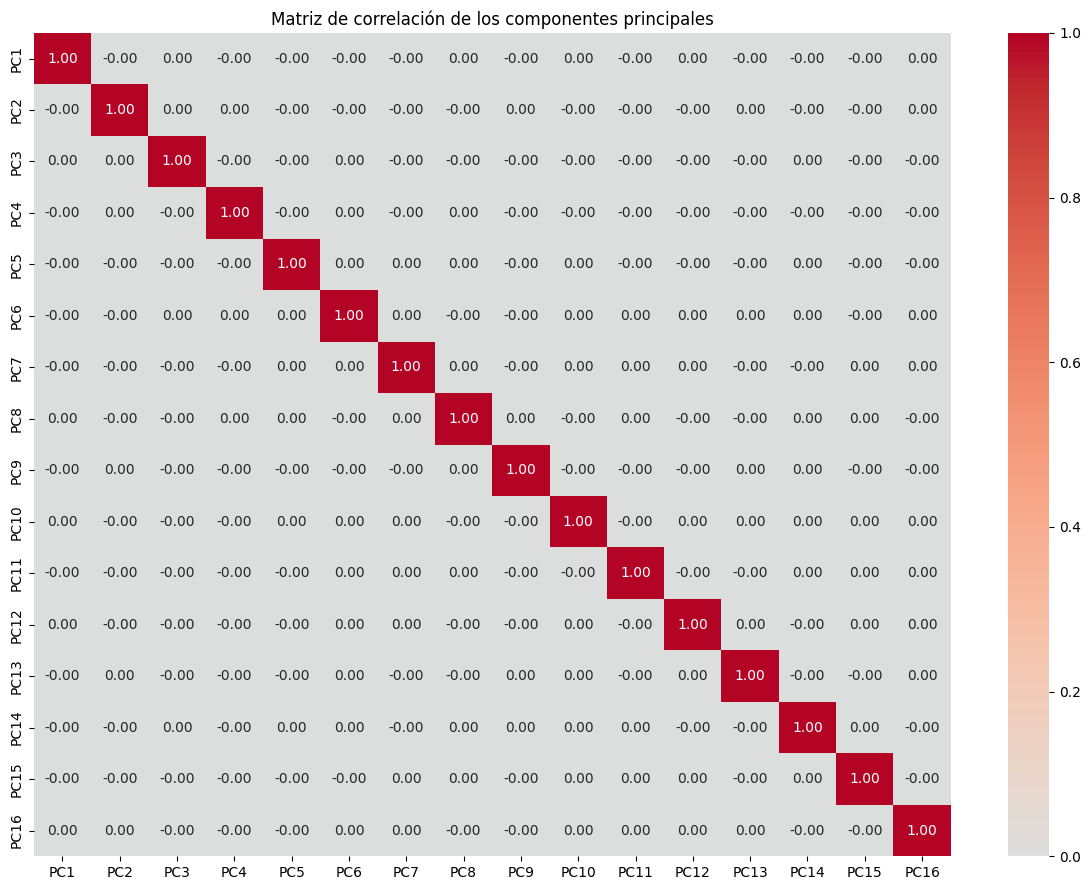

In [67]:
# Mapa de calor de correlaciones
plt.figure(figsize=(12, 9))

sns.heatmap(correlacion_pca, annot=True, fmt='.2f',
            cmap='coolwarm', center=0)

plt.title('Matriz de correlación de los componentes principales')
plt.tight_layout()
plt.show()

***Conclusión:***
En el mapa de calor de la matriz de correlaciones de `df_pca` se verifica que todos los coeficientes fuera de la diagonal principal son exactamente **`0.00`** (con **`1.00`** en la diagonal). Esto confirma que los 16 componentes principales (`PC1` a `PC16`) son **ortogonales y linealmente independientes entre sí**, resolviendo por completo la multicolinealidad detectada entre los predictores numéricos originales.

7. Obtén el porcentaje de varianza explicada por cada componente.
* Grafica la curva de varianza acumulada para determinar el número mínimo de componentes principales que explican más del 90% de la varianza total.

Paso 1. Obtención de la varianza explicada por cada componente.

In [68]:
varianza_explicada = pca.explained_variance_ratio_ * 100

Paso 2. Obtención de la varianza acumulada

In [69]:
varianza_acumulada = np.cumsum(varianza_explicada)

Paso 3. Generación del dataframe de resultados.

In [70]:
varianza_df = pd.DataFrame({
    'Componente': pc_names,
    'Varianza explicada (%)': varianza_explicada,
    'Varianza acumulada (%)': varianza_acumulada
}).round(2)

varianza_df

,Componente,Varianza explicada (%),Varianza acumulada (%)
0,PC1,44.55,44.55
1,PC2,17.93,62.48
2,PC3,8.58,71.05
3,PC4,6.44,77.49
4,PC5,5.74,83.23
5,PC6,4.78,88.01
6,PC7,3.25,91.26
7,PC8,2.73,93.98
8,PC9,1.94,95.92
9,PC10,1.55,97.48


**Punto 1.** Gráfica de la curva de varianza acumulada para la identificación de los principales componentes que explican más del 90% de la varianza total.

Paso 1. Identificamos el primer componente que supera el 90 %

In [71]:
componentes_90 = np.argmax(varianza_acumulada > 90) + 1
valor_90 = varianza_acumulada[componentes_90 - 1]

Paso 2. Graficamos.

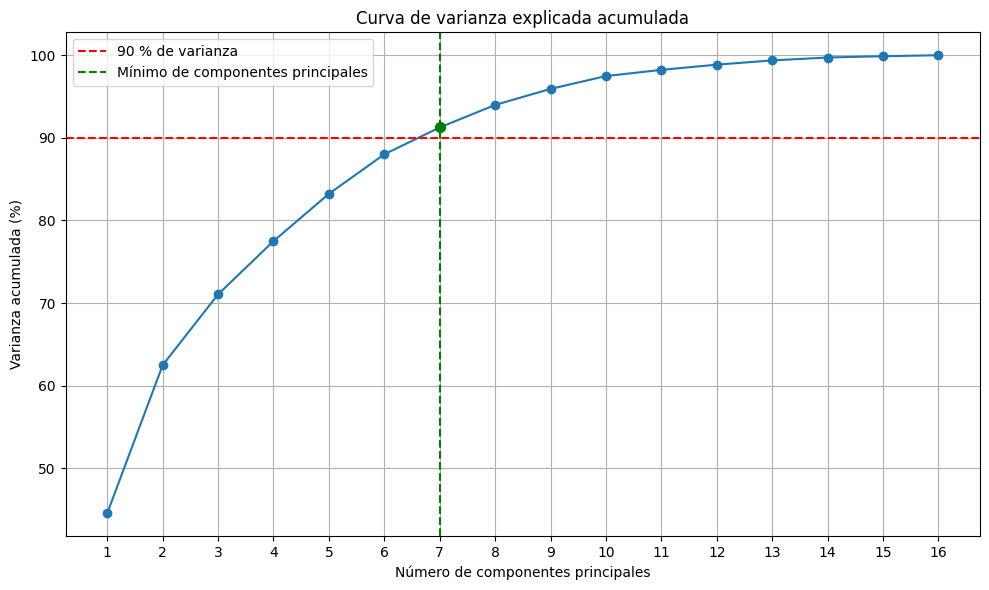

In [72]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada,
    marker='o'
)

plt.axhline(y=90, color='red', linestyle='--', label='90 % de varianza')

plt.axvline(x=componentes_90, color='green', linestyle='--', label='Mínimo de componentes principales')

plt.scatter(componentes_90, valor_90, color='green', s=50, zorder=5)

plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza acumulada (%)')
plt.title('Curva de varianza explicada acumulada')
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

***Conclusión:***

* **Porcentaje de varianza explicada individual:** El primer componente (`PC1`) concentra el **44.55%** de la varianza total, seguido de `PC2` (**17.93%**), `PC3` (**8.58%**), `PC4` (**6.44%**), `PC5` (**5.74%**), `PC6` (**4.78%**) y `PC7` (**3.25%**). Del `PC8` al `PC16`, cada componente aporta menos del 2.8% de varianza.
* **Número mínimo de componentes que explican más del 90% de la varianza total:** La curva acumulada muestra que con 6 componentes se captura el `88.01%` (inferior al 90%), mientras que al incorporar el séptimo componente se alcanza el **91.26%**. Por consiguiente, **el número mínimo requerido es de 7 componentes principales (`PC1` a `PC7`)**, logrando reducir la dimensionalidad numérica de 16 a 7 variables (una reducción del **56.25%**) conservando más del 91% de la información original.

8. Imprime la información de los componentes seleccionados (cargas o pesos de las variables originales) para interpretar qué variables contribuyen más a cada componente principal.
* Dibuja un diagrama de barras que muestre qué variables originales aportan más al primer componente principal (PC1), para visualizar su influencia relativa.

Paso 1. Obtención de las cargas de las variables originales.

In [73]:
cargas_pca = pd.DataFrame(
    pca.components_[:componentes_90],
    columns=X.columns,
    index=pc_names[:componentes_90]
).T.round(3)

cargas_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
symboling,-0.097,-0.403,0.265,-0.072,-0.366,0.173,0.128
normalized_losses,0.016,-0.331,0.308,-0.343,-0.376,-0.492,-0.323
wheel_base,0.298,0.265,-0.029,-0.228,-0.004,-0.183,-0.106
length,0.338,0.139,-0.044,-0.194,-0.074,-0.082,-0.009
width,0.334,0.055,0.109,-0.098,-0.016,-0.107,0.140
height,0.114,0.422,-0.282,-0.186,-0.017,-0.214,-0.003
curb_weight,0.362,0.022,0.080,-0.025,-0.042,-0.014,0.061
num_cylinders,0.245,-0.114,0.177,0.552,0.237,-0.354,-0.068
engine_size,0.330,-0.082,0.199,0.296,0.109,0.016,-0.073
bore,0.263,0.003,-0.138,0.041,-0.373,0.512,0.126


Paso 2. Demostración de las 5 variables de mayor peso absoluto por componente.

In [74]:
top_cargas = pd.DataFrame({
    col: cargas_pca[col].abs().nlargest(5).index for col in cargas_pca.columns
})

top_cargas


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,curb_weight,height,stroke,num_cylinders,stroke,bore,compression_ratio
1,length,symboling,compression_ratio,stroke,normalized_losses,normalized_losses,peak_rpm
2,width,peak_rpm,normalized_losses,normalized_losses,bore,stroke,normalized_losses
3,engine_size,compression_ratio,height,engine_size,symboling,num_cylinders,horsepower
4,highway_mpg,normalized_losses,symboling,peak_rpm,peak_rpm,peak_rpm,stroke


**Punto 1.** Diagrama de barras con las variables originales que aportan más al primer componente principal (`PC1`)

Paso 1. Ordenamos las cargas de PC1 por su valor absoluto.

In [75]:
pc1 = cargas_pca['PC1'].sort_values(key=abs, ascending=False)

Paso 2. Diagrama de barras de las cargas de `PC1`.

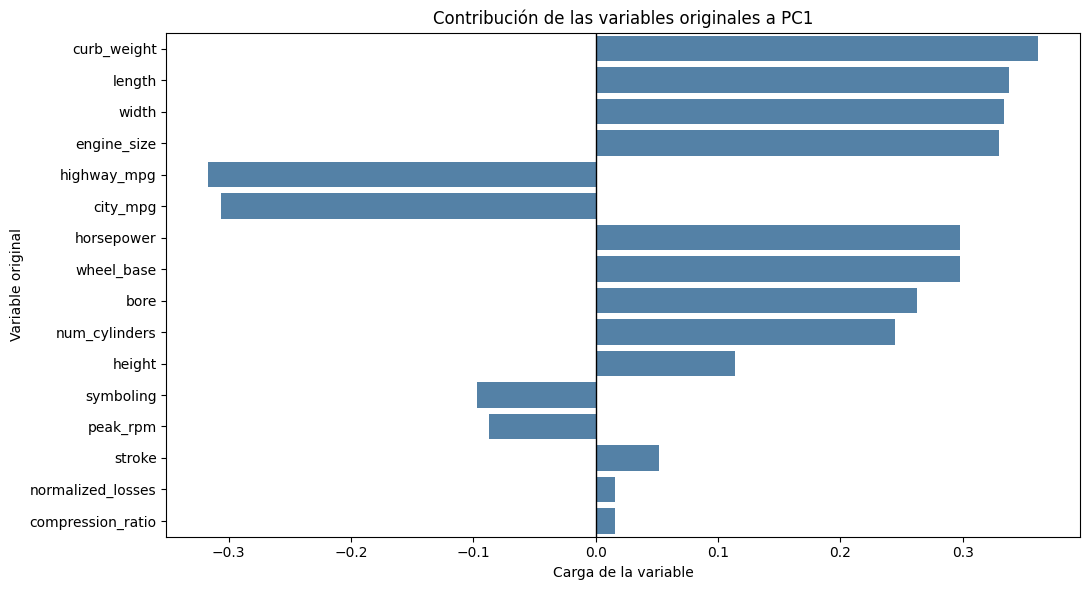

In [76]:
plt.figure(figsize=(11, 6))

sns.barplot(x=pc1.values, y=pc1.index, color='steelblue')

plt.axvline(0, color='black', linewidth=1)
plt.title('Contribución de las variables originales a PC1')
plt.xlabel('Carga de la variable')
plt.ylabel('Variable original')
plt.tight_layout()
plt.show()

***Interpretación:***

*   ***PC1 (44.55% de la varianza)** representa el **tamaño y potencia** del vehículo: tiene cargas positivas altas en curb_weight, length, width, engine_size, wheel_base y horsepower, y cargas negativas en city_mpg y highway_mpg. Es decir, valores altos de PC1 corresponden a autos más grandes, pesados y potentes, pero con menor rendimiento de combustible.*
*   ***PC2 (17.93%)** se asocia con la **altura y el perfil de riesgo**: carga positiva en height y compression_ratio, y negativa en symboling, peak_rpm y normalized_losses. Valores altos corresponden a autos más altos y de menor riesgo para la aseguradora.*
*   ***PC3 a PC7** capturan características mecánicas más específicas (stroke, compression_ratio, bore, num_cylinders, peak_rpm) y la variable normalized_losses, cada uno con menos del 9% de la varianza.*

*El diagrama de barras confirma que en PC1 casi todas las variables de dimensiones y motor aportan con un peso similar (alrededor de 0.3), por lo que este componente resume el "tamaño general" del automóvil, que también fueron las variables más correlacionadas con el precio.*

9. Codifica las variables categóricas mediante *One-Hot Encoding* y utiliza el parámetro `drop='first'` para evitar problemas de multicolinealidad entre las variables dummy generadas.

Paso 1. Seleccionamos de las variables categóricas.

In [77]:
X_cat = cars_df[cat_cols]

Paso 2. Codificamos las categorías, eliminando la primera de cada variable.

In [78]:
encoder = OneHotEncoder(drop='first', sparse_output=False)

X_encoded = pd.DataFrame(
    encoder.fit_transform(X_cat),
    columns=encoder.get_feature_names_out(X_cat.columns),
    index=cars_df.index
)

Paso 3. Revisamos el resultado.

In [79]:
print("Variables categóricas originales:", X_cat.shape[1])
print("Columnas después de One-Hot Encoding:", X_encoded.shape[1])

X_encoded.head()


Variables categóricas originales: 9
Columnas después de One-Hot Encoding: 44


,make_audi,make_bmw,make_chevrolet,make_dodge,make_honda,make_isuzu,make_jaguar,make_mazda,make_mercedes-benz,make_mercury,...,engine_type_ohcf,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


10. Conjunta, en un dataframe, las valores proyectados en los componentes seleccionados (mínimo), las transformaciones obtenidas de las variables categóricas y la variable de salida.
* Almacena el dataframe resultante en archivo.

Paso 1. Seleccionamos únicamente los componentes necesarios.

In [80]:
X_pca_selected = pca_df.iloc[:, :componentes_90]

Paso 2. Unimos los componentes, las variables codificadas y el precio.

In [81]:
cars_final = pd.concat(
    [X_pca_selected, X_encoded, y],
    axis=1
)

Paso 3. Verificamos las dimensiones y los primeros registros.

In [82]:
print("Dimensiones finales:", cars_final.shape)
display(cars_final.head())

Dimensiones finales: (205, 52)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,make_audi,make_bmw,make_chevrolet,...,engine_type_ohcv,engine_type_rotor,fuel_system_2bbl,fuel_system_4bbl,fuel_system_idi,fuel_system_mfi,fuel_system_mpfi,fuel_system_spdi,fuel_system_spfi,price
0,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13495
1,-0.918474,-2.397150,-0.410501,1.416623,-1.822817,1.203190,0.369729,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
2,0.634430,-1.372747,0.872496,0.998222,1.834717,-0.774751,-0.515065,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,16500
3,-0.361470,-0.919214,0.451578,-1.489124,-0.269938,-0.789900,0.000484,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13950
4,1.172393,-1.794960,0.183773,-1.083812,0.113486,-0.861858,-0.353900,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,17450


Paso 4. Comprobamos que no existan valores faltantes.

In [83]:
print("Valores faltantes:", cars_final.isna().sum().sum())

Valores faltantes: 0


Paso 5. Guardamos el DataFrame final en CSV.

In [84]:
cars_final.to_csv('automobile_processed.csv', index=False)

---

**Declaración de uso de IA**

*    OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/
---